# CASIA-FASD - Análise e Investigação do Dataset

## Objetivo

Analisar a versão pré-processada do **CASIA-FASD** utilizada neste trabalho.

Nesta análise serão consideradas principalmente as imagens RGB presentes nas pastas `color`.

### Informação a analisar

- estrutura do dataset;
- número de imagens;
- split (`train` / `test`);
- classe (`bona_fide` / `spoof`);
- sujeitos;
- tipo de ataque;
- qualidade de captura;
- resolução das imagens;
- correspondência entre imagens `color` e `depth`.

In [49]:
from pathlib import Path

import pandas as pd
from PIL import Image
from IPython.display import display

DATASET_PATH = Path(
    r"C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE\Datasets\CASIA_FASD"
)

TRAIN_PATH = DATASET_PATH / "train_img" / "train_img"
TEST_PATH = DATASET_PATH / "test_img" / "test_img"

TRAIN_COLOR = TRAIN_PATH / "color"
TEST_COLOR = TEST_PATH / "color"

TRAIN_DEPTH = TRAIN_PATH / "depth"
TEST_DEPTH = TEST_PATH / "depth"

print("Train:", TRAIN_PATH.exists())
print("Test:", TEST_PATH.exists())

Train: True
Test: True


## 1. Estrutura do dataset

A versão utilizada encontra-se dividida em `train` e `test`.

Cada split contém duas pastas:

- `color` — imagens RGB;
- `depth` — imagens de profundidade fornecidas nesta versão pré-processada.

A análise principal será realizada sobre as imagens RGB.

In [50]:
train_color_files = list(TRAIN_COLOR.glob("*.jpg"))
test_color_files = list(TEST_COLOR.glob("*.jpg"))

train_depth_files = list(TRAIN_DEPTH.glob("*.jpg"))
test_depth_files = list(TEST_DEPTH.glob("*.jpg"))

print("RGB:")
print("Train:", len(train_color_files))
print("Test:", len(test_color_files))
print("Total:", len(train_color_files) + len(test_color_files))

print("\nDepth:")
print("Train:", len(train_depth_files))
print("Test:", len(test_depth_files))
print("Total:", len(train_depth_files) + len(test_depth_files))

RGB:
Train: 1655
Test: 2408
Total: 4063

Depth:
Train: 1655
Test: 2408
Total: 4063


In [51]:
train_files = [f for f in TRAIN_PATH.rglob("*") if f.is_file()]
test_files = [f for f in TEST_PATH.rglob("*") if f.is_file()]

print("Train:", len(train_files))
print("Test:", len(test_files))
print("Total:", len(train_files) + len(test_files))

Train: 3310
Test: 4816
Total: 8126


In [52]:
from collections import Counter

train_extensions = Counter(f.suffix.lower() for f in train_files)
test_extensions = Counter(f.suffix.lower() for f in test_files)

print("Train:")
print(train_extensions)

print("\nTest:")
print(test_extensions)

Train:
Counter({'.jpg': 3310})

Test:
Counter({'.jpg': 4816})


## 2. Informação presente nos nomes dos ficheiros

Os nomes dos ficheiros preservam informação sobre o vídeo original.

Exemplos:

`10_1.avi_100_real.jpg`

`10_3.avi_50_fake.jpg`

`10_HR_2.avi_100_fake.jpg`

A partir destes nomes é possível recuperar:

- sujeito;
- vídeo original;
- número do frame;
- classe;
- tipo de ataque;
- qualidade de captura.

In [53]:
VIDEO_INFO = {
    "1":    ("bona_fide", None, "normal"),
    "2":    ("bona_fide", None, "low"),
    "HR_1": ("bona_fide", None, "high"),

    "3":    ("spoof", "warped_photo", "normal"),
    "4":    ("spoof", "warped_photo", "low"),
    "HR_2": ("spoof", "warped_photo", "high"),

    "5":    ("spoof", "cut_photo", "normal"),
    "6":    ("spoof", "cut_photo", "low"),
    "HR_3": ("spoof", "cut_photo", "high"),

    "7":    ("spoof", "video_replay", "normal"),
    "8":    ("spoof", "video_replay", "low"),
    "HR_4": ("spoof", "video_replay", "high")
}

In [54]:
#funcao para interpretar o filename
def parse_filename(filename):

    name = filename.replace(".jpg", "")
    parts = name.split("_")

    subject = parts[0]

    if parts[1] == "HR":
        video_code = f"HR_{parts[2].replace('.avi', '')}"
        frame_number = parts[3]
    else:
        video_code = parts[1].replace(".avi", "")
        frame_number = parts[2]

    label, attack_type, quality = VIDEO_INFO[video_code]

    return subject, video_code, frame_number, label, attack_type, quality

In [55]:
print(parse_filename("10_3.avi_50_fake.jpg"))
print(parse_filename("10_HR_2.avi_100_fake.jpg"))

('10', '3', '50', 'spoof', 'warped_photo', 'normal')
('10', 'HR_2', '100', 'spoof', 'warped_photo', 'high')


## 3. Criação do DataFrame

É criado um `DataFrame` com uma linha por frame RGB.

Cada imagem fica associada à respetiva classe, sujeito, split, tipo de ataque e qualidade.

In [56]:
rows = []

for split, folder in [
    ("train", TRAIN_COLOR),
    ("test", TEST_COLOR)
]:

    for file in folder.glob("*.jpg"):

        subject, video_code, frame_number, label, attack_type, quality = (
            parse_filename(file.name)
        )

        rows.append({
            "filepath": str(file),
            "filename": file.name,
            "subject": subject,
            "subject_id": f"{split}_{subject}",
            "split": split,
            "label": label,
            "class_id": 0 if label == "bona_fide" else 1,
            "video_code": video_code,
            "attack_type": attack_type if attack_type is not None else "none",
            "quality": quality,
            "frame_number": int(frame_number)
        })

df = pd.DataFrame(rows)

df.head()

,filepath,filename,subject,subject_id,split,label,class_id,video_code,attack_type,quality,frame_number
0,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,10_1.avi_100_real.jpg,10,train_10,train,bona_fide,0,1,none,normal,100
1,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,10_1.avi_25_real.jpg,10,train_10,train,bona_fide,0,1,none,normal,25
2,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,10_1.avi_50_real.jpg,10,train_10,train,bona_fide,0,1,none,normal,50
3,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,10_1.avi_75_real.jpg,10,train_10,train,bona_fide,0,1,none,normal,75
4,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,10_2.avi_100_real.jpg,10,train_10,train,bona_fide,0,2,none,low,100


## 4. Contagens principais

Nesta secção são analisadas:

- quantidade total de imagens RGB;
- distribuição `bona_fide` / `spoof`;
- distribuição entre `train` e `test`;
- qualidade de captura;
- tipos de ataque.

In [57]:
print("Total de imagens RGB:", len(df))

print("\nClasses:")
print(df["label"].value_counts())

print("\nTrain / Test:")
print(pd.crosstab(df["split"], df["label"]))

print("\nQualidade:")
print(df["quality"].value_counts())

print("\nTipos de ataque:")
print(df["attack_type"].value_counts(dropna=False))

Total de imagens RGB: 4063

Classes:
label
spoof        3068
bona_fide     995
Name: count, dtype: int64

Train / Test:
label  bona_fide  spoof
split                  
test         591   1817
train        404   1251

Qualidade:
quality
high      1480
normal    1294
low       1289
Name: count, dtype: int64

Tipos de ataque:
attack_type
warped_photo    1185
video_replay    1004
none             995
cut_photo        879
Name: count, dtype: int64


In [58]:
pd.crosstab(
    df["attack_type"],
    df["quality"]
)

quality,high,low,normal
attack_type,,,
cut_photo,246,350,283
none,390,314,291
video_replay,373,271,360
warped_photo,471,354,360


## 5. Análise dos sujeitos

São analisados os sujeitos presentes no dataset e a sua distribuição entre os conjuntos de treino e teste.

In [59]:
print("Total de sujeitos:", df["subject_id"].nunique())

print("\nSujeitos por split:")
print(
    df.groupby("split")["subject_id"].nunique()
)

Total de sujeitos: 50

Sujeitos por split:
split
test     30
train    20
Name: subject_id, dtype: int64


In [60]:
train_subjects = set(df[df["split"] == "train"]["subject"])
test_subjects = set(df[df["split"] == "test"]["subject"])

common_subjects = train_subjects & test_subjects

print("\nSujeitos presentes em train e test:")
print(sorted(common_subjects))


Sujeitos presentes em train e test:
['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '3', '4', '5', '6', '7', '8', '9']


## 6. Resolução das imagens

São analisadas as dimensões das imagens RGB utilizadas nesta versão do dataset.

In [61]:
sizes = []

for path in df["filepath"]:

    with Image.open(path) as img:
        sizes.append(img.size)

df[["width", "height"]] = sizes

print("Número de resoluções diferentes:")
print(len(df[["width", "height"]].drop_duplicates()))

print("\nResoluções:")
print(
    df[["width", "height"]]
    .value_counts()
)

print("\nLargura mínima:", df["width"].min())
print("Largura máxima:", df["width"].max())

print("Altura mínima:", df["height"].min())
print("Altura máxima:", df["height"].max())

Número de resoluções diferentes:
1

Resoluções:
width  height
256    256       4063
Name: count, dtype: int64

Largura mínima: 256
Largura máxima: 256
Altura mínima: 256
Altura máxima: 256


## 7. Correspondência entre Color e Depth

A versão descarregada contém uma imagem `depth` correspondente a cada imagem RGB.

É verificado se todos os ficheiros possuem efetivamente o respetivo par.

In [62]:
color_names = (
    {f.name for f in TRAIN_COLOR.glob("*.jpg")}
    |
    {f.name for f in TEST_COLOR.glob("*.jpg")}
)

depth_names = (
    {f.name for f in TRAIN_DEPTH.glob("*.jpg")}
    |
    {f.name for f in TEST_DEPTH.glob("*.jpg")}
)

print(
    "Color sem depth correspondente:",
    len(color_names - depth_names)
)

print(
    "Depth sem color correspondente:",
    len(depth_names - color_names)
)

Color sem depth correspondente: 0
Depth sem color correspondente: 0


## 8. Visualização de exemplos

São apresentados alguns exemplos das classes `bona_fide` e `spoof`.

A visualização é feita diretamente com Pillow/IPython, sem utilização de Matplotlib.


 BONA_FIDE
Sujeito: 7 | Split: train | Ataque: none | Qualidade: high | Resolução: 256x256


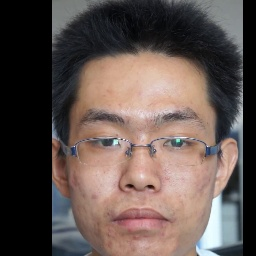

Sujeito: 1 | Split: test | Ataque: none | Qualidade: normal | Resolução: 256x256


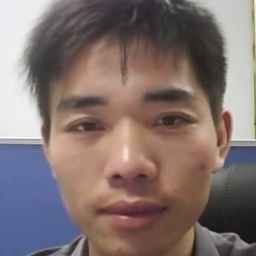

Sujeito: 29 | Split: test | Ataque: none | Qualidade: low | Resolução: 256x256


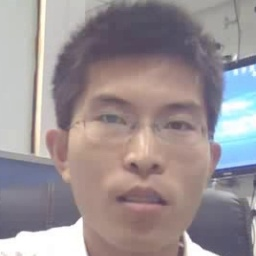


 SPOOF
Sujeito: 4 | Split: train | Ataque: cut_photo | Qualidade: low | Resolução: 256x256


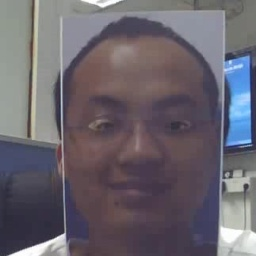

Sujeito: 10 | Split: train | Ataque: warped_photo | Qualidade: low | Resolução: 256x256


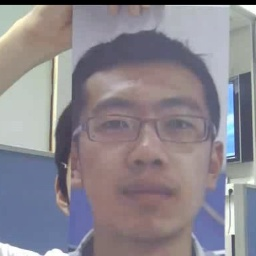

Sujeito: 27 | Split: test | Ataque: warped_photo | Qualidade: normal | Resolução: 256x256


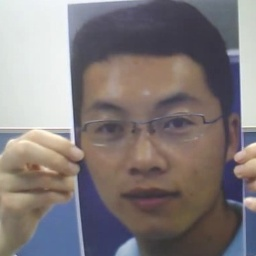

In [63]:
for label in ["bona_fide", "spoof"]:

    samples = df[df["label"] == label].sample(
        3,
        random_state=1
    )

    print("\n", label.upper())

    for _, row in samples.iterrows():

        img = Image.open(row["filepath"]).convert("RGB")

        print(
            "Sujeito:", row["subject"],
            "| Split:", row["split"],
            "| Ataque:", row["attack_type"],
            "| Qualidade:", row["quality"],
            "| Resolução:",
            f"{row['width']}x{row['height']}"
        )

        display(img)

## 9. Resumo do dataset

In [64]:
summary = pd.DataFrame({
    "Parametro": [
        "Total de imagens RGB",
        "Bona fide",
        "Spoof",
        "Train",
        "Test",
        "Sujeitos",
        "Tipos de ataque",
        "Níveis de qualidade",
        "Resoluções diferentes"
    ],
    "Valor": [
        len(df),
        (df["label"] == "bona_fide").sum(),
        (df["label"] == "spoof").sum(),
        (df["split"] == "train").sum(),
        (df["split"] == "test").sum(),
        df["subject"].nunique(),
        df["attack_type"].nunique(),
        df["quality"].nunique(),
        len(df[["width", "height"]].drop_duplicates())
    ]
})

summary

,Parametro,Valor
0,Total de imagens RGB,4063
1,Bona fide,995
2,Spoof,3068
3,Train,1655
4,Test,2408
5,Sujeitos,30
6,Tipos de ataque,4
7,Níveis de qualidade,3
8,Resoluções diferentes,1


## 10. Exportação dos resultados

O `DataFrame` final é exportado para CSV para permitir a comparação posterior com os restantes datasets analisados.

In [65]:
df.to_csv(
    "results_datasets/casia_fasd_dataset_report.csv",
    index=False
)

print("Ficheiro criado: casia_fasd_dataset_report.csv")

Ficheiro criado: casia_fasd_dataset_report.csv


## Conclusão

A versão analisada do CASIA-FASD contém **4063 frames RGB**, acompanhados por
4063 imagens `depth`, divididos entre os conjuntos de treino e teste.

O dataset contém **50 sujeitos**, sendo 20 utilizados no treino e 30 no teste.
Os identificadores numéricos dos sujeitos são locais a cada split, pelo que
identificadores iguais em treino e teste não representam a mesma identidade.

Foram identificados três tipos de ataques de apresentação: `warped photo`,
`cut photo` e `video replay`, bem como três níveis de qualidade de captura:
`low`, `normal` e `high`.

A versão analisada encontra-se pré-processada, apresentando todas as imagens
RGB com resolução de **256x256 píxeis**. Existe ainda uma correspondência
direta entre cada imagem RGB e uma imagem `depth`.

O CASIA-FASD apresenta características particularmente relevantes para esta
dissertação, uma vez que permite analisar o desempenho dos modelos perante
diferentes tipos de ataque e diferentes níveis de qualidade de aquisição.
Além disso, é um dos datasets utilizados nos protocolos clássicos de
avaliação cross-domain de Face Anti-Spoofing.